In [57]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
from statsmodels.tsa.stattools import adfuller #check for day 2
from functools import wraps #for the decorator
import inspect #for the decorator
from scipy.linalg import null_space
from gauge_arbitrage import vf
from gauge_arbitrage import time_series

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Day 2 (10/27)
Day 1 was skipped because we didn't have the timeline for that day. Note: going forward there are not going to be many functions in the notebook. Most functions for this week will be in vf.py (this is for functions related to V&F specifically)\
This week, we are focused on implementing V&F section 4 and testing their algorithm.

In [45]:
rng = np.random.default_rng(seed=0)

Text(0.5, 1.0, 'Simulation with 20 log-normal random walks (compare to V&F)')

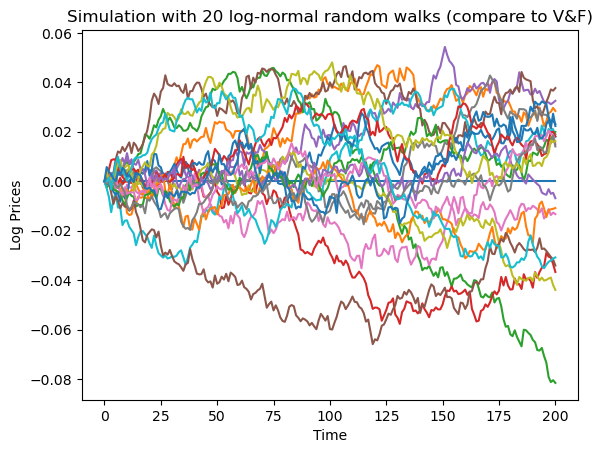

In [58]:
#test if the new package works (exact same code as 10_19.ipynb, but vf.X_mu_43)
beta_a=rng.uniform(low=-0.0001, high=0.0001, size=(18))
sigma=np.insert(rng.uniform(low=-0.001, high=0.001, size=(20, 18)),0,  np.zeros(18), axis=0)
alpha_A=rng.uniform(low=-0.0001, high=0.0001, size=(2))

#Compare to V&F Figure 1
fig_1, ax_1=plt.subplots(1,1)
rng2=np.random.default_rng()

#plot 20 random walks
for i in range(21):
    test=vf.X_mu_43(200, 200, sigma, beta_a, alpha_A, 1, i)
    ax_1.plot(test['Time'], np.log(test['Value']))
ax_1.set_xlabel('Time')
ax_1.set_ylabel('Log Prices')
ax_1.set_title('Simulation with 20 log-normal random walks (compare to V&F)')

In [114]:
#ISTG IF I GET ANOTHER VALUEERROR IM GONNA CRASH OUT
#implement these functions in the next two days
#im gonna move these to vf.py after were done

#equation 13/equation 85
def calc_G(Omega):
    #pls help me make this more efficient
    N=Omega.shape[0]
    u=np.matmul(np.ones((N, N)), Omega) #U(Omega)
    return Omega-(1/N)*(u+np.matmul(Omega, np.ones((N, N))))+(1/(N**2))*np.trace(u)*np.ones((N, N))

#compute eigenspace of G to get J vectors
def calc_J_G(Omega):
    G=calc_G(Omega)
    l=np.unique(np.linalg.eigvals(G))
    r=[]
    for i in l:
        e=null_space(G-i*np.eye(G.shape[0]))
        r.append(e)
    return np.column_stack(r)

#compute alpha A (equation 89)
def alpha_A_hat(X, Omega, dt):
    J=calc_J_G(Omega)
    np.sum(
        
    )
    pass

#compute A^2 hat
def A_2_hat():
    pass

def calc_Omega_hat():
    pass

In [121]:
omega=np.array([[0.44, 0.01], [100, 10]])

In [122]:
omega

array([[4.4e-01, 1.0e-02],
       [1.0e+02, 1.0e+01]])

In [123]:
np.sum(omega, axis=0)

array([100.44,  10.01])

In [120]:
omega[:, 1]

array([3, 0])

In [115]:
calc_J_G(omega)

array([[-0.70710678,  0.70710678],
       [ 0.70710678,  0.70710678]])

In [93]:
calc_G(omega)

array([[-1.5,  1.5],
       [ 1.5, -1.5]])

In [95]:
np.unique(np.linalg.eigvals(calc_G(omega)))

array([-3.00000000e+00, -2.22044605e-16])

In [78]:
np.matmul(omega, np.ones((2, 2)))

array([[3., 3.],
       [7., 7.]])